In [1]:
import urllib.request
import os

# Download the Adult Census Income dataset from UCI Repository
url_data = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
url_names = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.names'

print("Downloading Adult dataset...")
urllib.request.urlretrieve(url_data, 'adult.data')
urllib.request.urlretrieve(url_names, 'adult.names')
print("Download complete.")

Download complete.


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

df = pd.read_csv('adult.data', names=columns, header=None, skipinitialspace=True)

# 1. Clean data: Remove rows with "?"
df = df.replace('?', np.nan).dropna()

# Convert income target to binary (1 for >50K, 0 for <=50K)
df['income'] = df['income'].apply(lambda x: 1 if x.startswith('>50K') else 0)

# Separate features, target, and the sensitive attribute
X = df.drop(columns=['income'])
y = df['income']

# Keep sex as the sensitive attribute, but drop it from training features
sex_attribute = X['sex']
X_features = X.drop(columns=['sex'])

# Categorical and numerical columns
num_cols = X_features.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_features.select_dtypes(exclude=[np.number]).columns.tolist()

# Preprocessor: scale numeric, one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Stratified split: 70:30 ratio
X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X_features, y, sex_attribute, test_size=0.30, random_state=42, stratify=y
)

# Transform features
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

# Train Baseline Logistic Regression model
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_encoded, y_train)
y_pred_baseline = baseline_model.predict(X_test_encoded)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [4]:
!pip install -q fairlearn

In [5]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference

# Define metrics to compute
metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

# Fairlearn MetricFrame for the baseline model
metric_frame_baseline = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=sex_test
)

print("Baseline Fairness Audit Metrics by Group:")
display(metric_frame_baseline.by_group)

# Overall metrics
base_overall_acc = accuracy_score(y_test, y_pred_baseline)

# Parity metrics
dp_diff_baseline = demographic_parity_difference(y_test, y_pred_baseline, sensitive_features=sex_test)
dp_ratio_baseline = demographic_parity_ratio(y_test, y_pred_baseline, sensitive_features=sex_test)
eo_diff_baseline = equalized_odds_difference(y_test, y_pred_baseline, sensitive_features=sex_test)

print(f"Overall Accuracy: {base_overall_acc:.2f}")
print(f"Demographic parity difference: {dp_diff_baseline:.2f}")
print(f"Demographic parity ratio (DI): {dp_ratio_baseline:.2f}")
print(f"Equalized odds difference: {eo_diff_baseline:.2f}")

Baseline Fairness Audit Metrics by Group:


,accuracy,selection_rate,tpr,fpr
sex,,,,
Female,0.917728,0.088812,0.527378,0.029320
Male,0.812500,0.258626,0.614698,0.098608


Overall Accuracy: 0.85
Demographic parity difference: 0.17
Demographic parity ratio (DI): 0.34
Equalized odds difference: 0.09


In [6]:
from fairlearn.postprocessing import ThresholdOptimizer

# Helper to evaluate models quickly
def get_metrics_for_model(y_pred_model):
    mf = MetricFrame(
        metrics=metrics,
        y_true=y_test,
        y_pred=y_pred_model,
        sensitive_features=sex_test
    )
    acc = accuracy_score(y_test, y_pred_model)
    sel_m = mf.by_group.loc['Male', 'selection_rate']
    sel_f = mf.by_group.loc['Female', 'selection_rate']
    dp_diff = demographic_parity_difference(y_test, y_pred_model, sensitive_features=sex_test)
    eo_diff = equalized_odds_difference(y_test, y_pred_model, sensitive_features=sex_test)
    return acc, sel_m, sel_f, dp_diff, eo_diff

# 1. Demographic Parity Optimizer
to_dp = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="demographic_parity",
    predict_method="predict_proba"
)
to_dp.fit(X_train_encoded, y_train, sensitive_features=sex_train)
y_pred_dp = to_dp.predict(X_test_encoded, sensitive_features=sex_test)

# 2. Equalized Odds Optimizer
to_eo = ThresholdOptimizer(
    estimator=baseline_model,
    constraints="equalized_odds",
    predict_method="predict_proba"
)
to_eo.fit(X_train_encoded, y_train, sensitive_features=sex_train)
y_pred_eo = to_eo.predict(X_test_encoded, sensitive_features=sex_test)

# Gather results
results = []
for name, preds in [('Baseline', y_pred_baseline), ('TO: demographic_par.', y_pred_dp), ('TO: equalized_odds', y_pred_eo)]:
    acc, sel_m, sel_f, dp_diff, eo_diff = get_metrics_for_model(preds)
    results.append({
        'MODEL': name,
        'ACC': f"{acc:.2f}",
        'SEL_M': f"{sel_m:.2f}",
        'SEL_F': f"{sel_f:.2f}",
        'DP_DIFF': f"{dp_diff:.2f}",
        'EO_DIFF': f"{eo_diff:.2f}"
    })

results_df = pd.DataFrame(results)
display(results_df)

,MODEL,ACC,SEL_M,SEL_F,DP_DIFF,EO_DIFF
0,Baseline,0.85,0.26,0.09,0.17,0.09
1,TO: demographic_par.,0.83,0.17,0.17,0.00,0.31
2,TO: equalized_odds,0.83,0.22,0.12,0.09,0.03


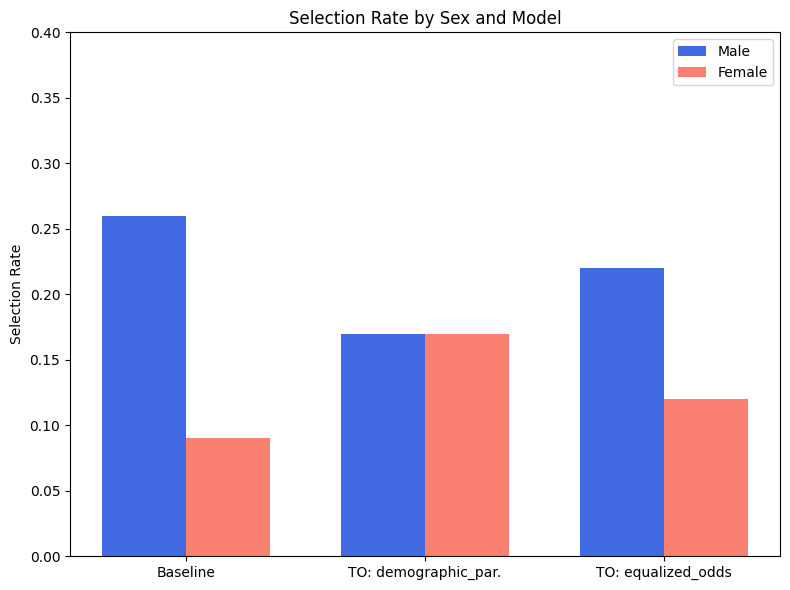

Plot saved successfully as selection_rate_by_sex.png


In [7]:
import matplotlib.pyplot as plt

# Prepare Data for Plotting
labels = ['Baseline', 'TO: demographic_par.', 'TO: equalized_odds']
male_selections = [float(results[0]['SEL_M']), float(results[1]['SEL_M']), float(results[2]['SEL_M'])]
female_selections = [float(results[0]['SEL_F']), float(results[1]['SEL_F']), float(results[2]['SEL_F'])]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6))
rects1 = ax.bar(x - width/2, male_selections, width, label='Male', color='royalblue')
rects2 = ax.bar(x + width/2, female_selections, width, label='Female', color='salmon')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex and Model')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 0.4)
ax.legend()

fig.tight_layout()
plt.savefig('selection_rate_by_sex.png', dpi=300)
plt.show()

print("Plot saved successfully as selection_rate_by_sex.png")